# UNSB 마무리 — 변환 단계 수(NFE) 고르기 + 최종 채점

**위에서부터 `Shift + Enter`만 누르면 됩니다. 고칠 값 없음** (고르는 것도 자동).

1. **val로 고르기**: 저장된 epoch(5~50) × 변환 단계 수(NFE 1·2·3·5) 중 val RBC F1이 가장 높은 조합을 자동 선택
   - NFE = UNSB가 비염색을 염색으로 몇 단계에 걸쳐 바꾸는지. 논문에서도 단계가 많으면 과하게 바뀌는(가짜 세포가 생기는) 경우가 있다고 함
   - NFE 5는 이미 돌린 결과를 그대로 씀. 이미 끝난 조합은 건너뜀 (중간에 끊겨도 다시 실행하면 이어서 함)
2. **test 한 번**: 고른 조합으로만 test 91장 채점
3. **최종 비교표**: 하한 · CycleGAN 1차 · UNSB
   - 메인 지표: 지금까지와 같은 규칙
   - 보조 지표: 테두리에 걸쳐 잘린 세포를 정답·예측 모두에서 빼고 채점 (`--border 6`, 세 방법에 똑같이). 결과를 보고 추가한 지표라서 보고서에는 보조로만 적기
4. 그림 비교

예상 시간: 1번 30분~1시간 (GPU), 나머지 수 분. 결과는 `results/3_staining/unsb/`, 보조 지표는 `results/5_secondary_border/`.

In [1]:
import torch, os, sys, json, pandas as pd
print('GPU:', torch.cuda.is_available())
os.chdir(r'D:\05. Blood\05. Train\code')
UREPO = r"D:/05. Blood/05. Train/external/unsb"; T = r"D:/05. Blood/05. Train"; P = r"D:/05. Blood/04. Prep"
R = T + "/results/3_staining/unsb"

GPU: True


## 1. val로 epoch × NFE 고르기 (자동)

In [2]:
EPOCHS = list(range(5, 51, 5))
NFES = [1, 2, 3, 5]
def val_dir(e, k):   # NFE 5는 예전 결과 폴더(ep<e>_val) 그대로 사용
    return f"{R}/ep{e}_val" if k == 5 else f"{R}/ep{e}_nfe{k}_val"
for e in EPOCHS:
    for k in NFES:
        out = val_dir(e, k)
        if os.path.exists(out + "/summary.csv"):
            continue
        vs = f"{T}/virtual_stained/unsb/ep{e}_nfe{k}/val"
        !{sys.executable} 23_apply_unsb.py --repo "{UREPO}" --ckpt "{T}/runs/unsb/unsb_rbc" --epoch {e} --nfe {k} --images "{P}/4_eval_unstained/redtell_dse_val/images" --out "{vs}"
        !{sys.executable} 12_eval_compare.py --prep "{P}" --images "{vs}" --labels "{P}/4_eval_unstained/redtell_dse_val/labels" --yolo "D:/05. Blood/05. Train/runs/yolo/yolo11s/weights/best.pt" --conf 0.7 --out "{out}"

UNSB 가상 염색 9장 완료 (epoch 5, NFE 1, 조각 128, 장당 1065 ms) → D:/05. Blood/05. Train/virtual_stained/unsb/ep5_nfe1/val

[YOLO]
  method: YOLO
  n_images: 9
  WBC_MAE: 0.0
  WBC_precision: 0.0
  WBC_recall: 0.0
  WBC_F1: 0.0
  RBC_MAE: 6.556
  RBC_precision: 0.7778
  RBC_recall: 0.8905
  RBC_F1: 0.8303
  WBC_rel_error: 
  RBC_rel_error: 0.2079
  ms_per_image: 13.4

����옣: D:/05. Blood/05. Train/results/3_staining/unsb/ep5_nfe1_val
UNSB 가상 염색 9장 완료 (epoch 5, NFE 2, 조각 128, 장당 2168 ms) → D:/05. Blood/05. Train/virtual_stained/unsb/ep5_nfe2/val

[YOLO]
  method: YOLO
  n_images: 9
  WBC_MAE: 0.0
  WBC_precision: 0.0
  WBC_recall: 0.0
  WBC_F1: 0.0
  RBC_MAE: 8.0
  RBC_precision: 0.7488
  RBC_recall: 0.8905
  RBC_F1: 0.8135
  WBC_rel_error: 
  RBC_rel_error: 0.2777
  ms_per_image: 8.9

����옣: D:/05. Blood/05. Train/results/3_staining/unsb/ep5_nfe2_val
UNSB 가상 염색 9장 완료 (epoch 5, NFE 3, 조각 128, 장당 3266 ms) → D:/05. Blood/05. Train/virtual_stained/unsb/ep5_nfe3/val

[YOLO]
  method: YOLO
  n_images:

In [3]:
rows = []
for e in EPOCHS:
    for k in NFES:
        d = pd.read_csv(val_dir(e, k) + "/summary.csv").iloc[0]
        rows.append({"epoch": e, "NFE": k, "RBC_MAE": d.RBC_MAE, "RBC_precision": d.RBC_precision, "RBC_recall": d.RBC_recall, "RBC_F1": d.RBC_F1})
tab = pd.DataFrame(rows)
display(tab.pivot(index="epoch", columns="NFE", values="RBC_F1").style.format("{:.3f}").highlight_max(axis=None, color="#c8e6c9"))
best = tab.sort_values(["RBC_F1", "RBC_MAE"], ascending=[False, True]).iloc[0]
BEST_E, BEST_K = int(best.epoch), int(best.NFE)
none_val = pd.read_csv(T + "/results/2_no_staining/stain_none_val/summary.csv").iloc[0]
print(f"val 최고: epoch {BEST_E}, NFE {BEST_K} → RBC F1 {best.RBC_F1:.3f}, MAE {best.RBC_MAE:.2f}  (가상 염색 없음: F1 {none_val.RBC_F1:.3f}, MAE {none_val.RBC_MAE:.2f})")
json.dump({"epoch": BEST_E, "nfe": BEST_K, "val": best.to_dict(), "rule": "val RBC F1 최고 (동점이면 MAE 낮은 쪽)"}, open(R + "/selected.json", "w"), indent=1, default=float)

NFE,1,2,3,5
epoch,,,,
5,0.830,0.814,0.812,0.797
10,0.806,0.766,0.766,0.767
15,0.860,0.832,0.838,0.823
20,0.819,0.802,0.783,0.782
25,0.845,0.829,0.832,0.819
30,0.829,0.798,0.788,0.777
35,0.841,0.802,0.797,0.778
40,0.832,0.807,0.798,0.792
45,0.828,0.793,0.790,0.783


val 최고: epoch 15, NFE 1 → RBC F1 0.860, MAE 4.44  (가상 염색 없음: F1 0.824, MAE 10.11)


## 2. test 한 번 (고른 조합으로만)

In [4]:
TEST_DIR = f"{R}/ep{BEST_E}_nfe{BEST_K}_test"
VS_TEST = f"{T}/virtual_stained/unsb/ep{BEST_E}_nfe{BEST_K}/test"
if not os.path.exists(TEST_DIR + "/summary.csv"):
    !{sys.executable} 23_apply_unsb.py --repo "{UREPO}" --ckpt "{T}/runs/unsb/unsb_rbc" --epoch {BEST_E} --nfe {BEST_K} --images "{P}/4_eval_unstained/redtell_dse/images" --out "{VS_TEST}"
    !{sys.executable} 12_eval_compare.py --prep "{P}" --images "{VS_TEST}" --labels "{P}/4_eval_unstained/redtell_dse/labels" --yolo "D:/05. Blood/05. Train/runs/yolo/yolo11s/weights/best.pt" --conf 0.7 --out "{TEST_DIR}"

UNSB 가상 염색 91장 완료 (epoch 15, NFE 1, 조각 128, 장당 1083 ms) → D:/05. Blood/05. Train/virtual_stained/unsb/ep15_nfe1/test

[YOLO]
  method: YOLO
  n_images: 91
  WBC_MAE: 0.0
  WBC_precision: 0.0
  WBC_recall: 0.0
  WBC_F1: 0.0
  RBC_MAE: 6.231
  RBC_precision: 0.7626
  RBC_recall: 0.881
  RBC_F1: 0.8175
  WBC_rel_error: 
  RBC_rel_error: 0.2241
  ms_per_image: 12.4

����옣: D:/05. Blood/05. Train/results/3_staining/unsb/ep15_nfe1_test


## 3. 최종 비교표 (test 91장)

In [5]:
inputs = {"비염색 그대로 (하한)": (P + "/4_eval_unstained/redtell_dse/images", T + "/results/2_no_staining/stain_none_test"),
          "CycleGAN 1차 ep15": (T + "/virtual_stained/cyclegan/ep15/test", T + "/results/3_staining/cyclegan/ep15_test"),
          f"UNSB ep{BEST_E} NFE{BEST_K}": (VS_TEST, TEST_DIR)}
B = T + "/results/5_secondary_border"
for name, (img, _) in inputs.items():
    tag = {0: "none", 1: "cyclegan_ep15", 2: f"unsb_ep{BEST_E}_nfe{BEST_K}"}[list(inputs).index(name)]
    if not os.path.exists(f"{B}/{tag}/summary.csv"):
        !{sys.executable} 12_eval_compare.py --prep "{P}" --images "{img}" --labels "{P}/4_eval_unstained/redtell_dse/labels" --yolo "D:/05. Blood/05. Train/runs/yolo/yolo11s/weights/best.pt" --conf 0.7 --border 6 --out "{B}/{tag}"
cols = ["RBC_MAE", "RBC_precision", "RBC_recall", "RBC_F1"]
main_t = pd.DataFrame({n: pd.read_csv(d + "/summary.csv").iloc[0][cols] for n, (_, d) in inputs.items()}).T
tags = ["none", "cyclegan_ep15", f"unsb_ep{BEST_E}_nfe{BEST_K}"]
bord_t = pd.DataFrame({n: pd.read_csv(f"{B}/{t}/summary.csv").iloc[0][cols] for n, t in zip(inputs, tags)}).T
print("메인 지표 (지금까지와 같은 규칙)"); display(main_t)
print("보조 지표 (테두리에 걸친 세포 제외, 세 방법 똑같이)"); display(bord_t)
main_t.to_csv(T + "/results/final_compare_main.csv", encoding="utf-8-sig"); bord_t.to_csv(T + "/results/final_compare_border6.csv", encoding="utf-8-sig")


[YOLO]
  method: YOLO
  n_images: 91
  WBC_MAE: 0.0
  WBC_precision: 0.0
  WBC_recall: 0.0
  WBC_F1: 0.0
  RBC_MAE: 6.879
  RBC_precision: 0.9816
  RBC_recall: 0.7534
  RBC_F1: 0.8525
  WBC_rel_error: 
  RBC_rel_error: 0.2445
  ms_per_image: 10.5

����옣: D:/05. Blood/05. Train/results/5_secondary_border/none

[YOLO]
  method: YOLO
  n_images: 91
  WBC_MAE: 0.0
  WBC_precision: 0.0
  WBC_recall: 0.0
  WBC_F1: 0.0
  RBC_MAE: 5.824
  RBC_precision: 0.7169
  RBC_recall: 0.8462
  RBC_F1: 0.7762
  WBC_rel_error: 
  RBC_rel_error: 0.2914
  ms_per_image: 10.5

����옣: D:/05. Blood/05. Train/results/5_secondary_border/cyclegan_ep15

[YOLO]
  method: YOLO
  n_images: 91
  WBC_MAE: 0.0
  WBC_precision: 0.0
  WBC_recall: 0.0
  WBC_F1: 0.0
  RBC_MAE: 3.736
  RBC_precision: 0.7855
  RBC_recall: 0.8581
  RBC_F1: 0.8202
  WBC_rel_error: 
  RBC_rel_error: 0.1822
  ms_per_image: 11.3

����옣: D:/05. Blood/05. Train/results/5_secondary_border/unsb_ep15_nfe1
메인 지표 (지금까지와 같은 규칙)


,RBC_MAE,RBC_precision,RBC_recall,RBC_F1
비염색 그대로 (하한),9.846,0.9736,0.7252,0.8313
CycleGAN 1차 ep15,7.769,0.7073,0.8388,0.7675
UNSB ep15 NFE1,6.231,0.7626,0.881,0.8175


보조 지표 (테두리에 걸친 세포 제외, 세 방법 똑같이)


,RBC_MAE,RBC_precision,RBC_recall,RBC_F1
비염색 그대로 (하한),6.879,0.9816,0.7534,0.8525
CycleGAN 1차 ep15,5.824,0.7169,0.8462,0.7762
UNSB ep15 NFE1,3.736,0.7855,0.8581,0.8202


## 4. 그림 비교 (초록 선 = 실제 세포 위치)

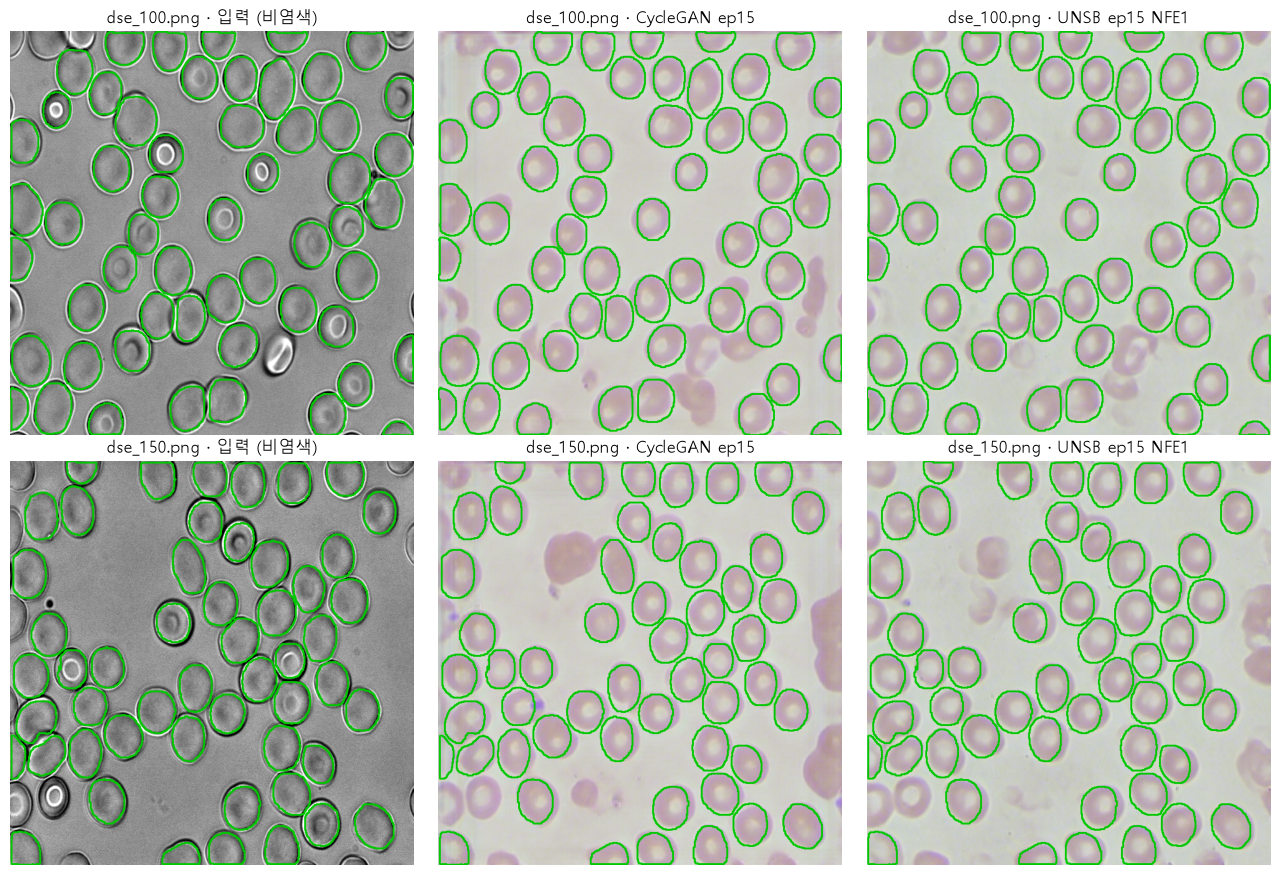

In [6]:
import matplotlib.pyplot as plt, numpy as np, cv2
plt.rcParams["font.family"] = "Malgun Gothic"; plt.rcParams["axes.unicode_minus"] = False
rd = lambda p, f=1: cv2.imdecode(np.fromfile(p, np.uint8), f)
names = ["dse_100.png", "dse_150.png"]
fig, ax = plt.subplots(len(names), 3, figsize=(13, 4.4 * len(names)))
for i, n in enumerate(names):
    gt = rd(f"{P}/4_eval_unstained/redtell_dse/masks/{n}", -1)
    edge = np.zeros(gt.shape, np.uint8)
    for v in np.unique(gt)[1:]:
        c, _ = cv2.findContours((gt == v).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE); cv2.drawContours(edge, c, -1, 255, 2)
    ims = [cv2.cvtColor(rd(f"{P}/4_eval_unstained/redtell_dse/images/{n}", 0), cv2.COLOR_GRAY2RGB),
           cv2.cvtColor(rd(f"{T}/virtual_stained/cyclegan/ep15/test/{n}"), cv2.COLOR_BGR2RGB),
           cv2.cvtColor(rd(f"{VS_TEST}/{n}"), cv2.COLOR_BGR2RGB)]
    for j, (im, t) in enumerate(zip(ims, ["입력 (비염색)", "CycleGAN ep15", f"UNSB ep{BEST_E} NFE{BEST_K}"])):
        im = im.copy(); im[edge > 0] = (0, 200, 0)
        ax[i, j].imshow(im); ax[i, j].set_title(f"{n} · {t}"); ax[i, j].axis("off")
plt.tight_layout(); plt.show()